# One-channel instrument

Use the uninterrupted FANTASTIC elliptic guide and a 2–4 Å pulsed source.
Run from a fresh kernel, in cell order.


In [1]:
import mcstasscript as ms

workspace = Path.cwd().resolve()
build_directory = tempfile.TemporaryDirectory(prefix="one_channel_instrument-", dir="/tmp")

instr = ms.McStas_instr(
    "one_channel_instrument",
    author="McStasScript example",
    origin="Teaching example",
    input_path=build_directory.name,
    output_path=str(workspace / "one_channel_instrument"),
    executable_path=str(Path(sys.prefix) / "bin"),
)


## FANTASTIC primary guide and source range

The source emits wavelengths from **2 to 4 Å**. Its pulsed moderator model
and pulse-shape settings remain editable in the parameter cell below.
It targets the guide entrance 0.5 m away, using the existing 40 × 40 mm
source focus rectangle.

There is one uninterrupted `Elliptic_guide_gravity`, with the parameters
from FANTASTIC_kyriakos_TUBES:

| Setting | Value |
| --- | ---: |
| Guide length | 35 m |
| Horizontal / vertical dimensions at mid-length | 0.12 / 0.12 m |
| Horizontal upstream / downstream focal distances | 0.611423 / 1.68246 m |
| Vertical upstream / downstream focal distances | 1.04627 / 1.94531 m |
| Supermirror m / R0 | 4 / 0.99 |
| Gravity | Enabled |
| Source-to-guide / guide-to-sample distances | 0.5 / 1.5 m |

`dimensionsAt="mid"` is essential: the 0.12 m dimensions specify the
guide at its midpoint. Its entrance and exit apertures follow the ellipse.
There are no choppers or gaps inside the guide.

The nominal source-to-sample path is

$$L_i=d_{\mathrm{source,guide}}+L_{\mathrm{guide}}
+d_{\mathrm{guide,sample}}=0.5+35+1.5=37\ \mathrm{m}.$$

The sample and secondary components are constructed after this guide.


In [ ]:
pulse_length = 400.0e-6
instr.add_parameter("pulse_length", value=pulse_length,
                    comment="Proton pulse duration for the moderator model [s]")
moderator_tau = 170.0e-6
instr.add_parameter("moderator_tau", value=moderator_tau,
                    comment="Cold moderator decay time used by Source_pulsed [s]")
moderator_n = 5.0
instr.add_parameter("moderator_n", value=moderator_n,
                    comment="Cold moderator pulse-shape parameter used by Source_pulsed")
moderator_time_center = 0.5*pulse_length + moderator_tau*(moderator_n+1.0)/moderator_n
source_frequency = 50.0
instr.add_parameter("source_frequency", value=source_frequency,
                    comment="Source repetition rate [Hz]")
lambda_min = 2.0
instr.add_parameter("lambda_min", value=lambda_min,
                    comment="Minimum source wavelength [Angstrom]")
lambda_max = 4.0
instr.add_parameter("lambda_max", value=lambda_max,
                    comment="Maximum source wavelength [Angstrom]")


source_t_max = 0.004
instr.add_parameter("double", "source_t_max", value=source_t_max,
                    comment="End of Source_pulsed emission-time sampling window [s]")

# The uninterrupted elliptic guide f
guide_parameters = {
    "linx": (0.611423, "Horizontal upstream focal distance [m]"),
    "liny": (1.04627, "Vertical upstream focal distance [m]"),
    "loutx": (1.68246, "Horizontal downstream focal distance [m]"),
    "louty": (1.94531, "Vertical downstream focal distance [m]"),
    "guide_length": (35.0, "Length of the uninterrupted elliptic guide [m]"),
    "guide_xwidth": (0.12, "Horizontal guide dimension at mid-length [m]"),
    "guide_yheight": (0.12, "Vertical guide dimension at mid-length [m]"),
    "d_source_guide": (0.5, "Source-to-guide entrance distance [m]"),
    "d_guide_sample": (1.5, "Guide exit-to-sample distance [m]"),
}
for name, (value, comment) in guide_parameters.items():
    instr.add_parameter("double", name, value=value, comment=comment)

instr.append_initialize('if (lambda_min <= 0 || lambda_max <= lambda_min || source_frequency <= 0 || pulse_length <= 0 || moderator_tau <= 0 || moderator_n <= 1 || source_t_max <= 0) { fprintf(stderr, "Invalid source parameters\\n"); exit(1); }')
instr.append_initialize('if (guide_length <= 0 || guide_xwidth <= 0 || guide_yheight <= 0 || d_source_guide <= 0 || d_guide_sample < 0 || linx <= 0 || liny <= 0 || loutx <= 0 || louty <= 0) { fprintf(stderr, "Invalid elliptic-guide geometry\\n"); exit(1); }')


In [3]:
source = instr.add_component("source", "Source_pulsed")
source.xwidth = 0.042
source.yheight = 0.03
source.Lmin = "lambda_min"
source.Lmax = "lambda_max"
source.t_min = 0.0
source.t_max = "source_t_max"
source.dist = "d_source_guide"
source.focus_xw = 0.04
source.focus_yh = 0.04
source.freq = "source_frequency"
source.t_pulse = "pulse_length"
source.T1 = 60.0
source.I1 = "1.75e12/source_frequency"
source.tau1 = "moderator_tau"
source.n_mod = "moderator_n"
source.I_um = "3.82e10/source_frequency"
source.tau_um = 12.0e-6
source.n_um = 5.0
source.chi_um = 0.9
source.kap_um = 2.2

guide = instr.add_component(
    "guide", "Elliptic_guide_gravity",
    AT=[0, 0, "d_source_guide"], RELATIVE="source"
)
guide.xwidth = "guide_xwidth"
guide.yheight = "guide_yheight"
guide.l = "guide_length"
guide.linxw = "linx"
guide.loutxw = "loutx"
guide.linyh = "liny"
guide.loutyh = "louty"
guide.dimensionsAt = '"mid"'
guide.option = '"ellipse"'
guide.R0 = 0.99
guide.Qc = 0.0218
guide.alpha = 6.07
guide.m = 4
guide.W = 0.003



In [4]:
guide_out = instr.add_component(
    "guide_out", "Arm", AT=[0, 0, "guide_length"], RELATIVE="guide"
)
sample_position = instr.add_component(
    "sample_position", "Arm",
    AT=[0, 0, "d_guide_sample"], RELATIVE="guide_out"
)


## Add one analyser channel


| Parameter | Default | Meaning |
| --- | --- | --- |
| lambda_f | 4.2 Å | Analyser-selected final wavelength. |
| channel_angle | 30° | Sample-to-analyser direction; channel 0's offset in the reference. |
| d_sample_analyser | 0.8 m | Sample-to-analyser distance. |
| analyser_d | 3.357 Å | Graphite lattice spacing. |
| analyser_width, analyser_height | 0.07, 0.03 m | Total analyser dimensions. |
| analyser_mosaic_h/v | 30 arcmin | Horizontal/vertical mosaic. |
| analyser_NH/NV | 1, 1 | Blade counts. |
| analyser_gap | 0 m | Blade gap. |
| analyser_detector_distance | 0.5 m | Fixed detector-arm separation L2; the ray path is L2/sin(2A5). |
| detector_x, detector_y | 0.03, 0.5 m | Pair width and tube height. Each tube diameter is half the pair width. |
| sample_radius, sample_height | 0.01, 0.02 m | Graphite sample dimensions. |
| sample_rotation_x/y/z | 0°, 0°, 0° | Sample orientation from the supplied reference. |




In [5]:
channel_parameters = {
    "lambda_f": (4.2, "Analyser-selected wavelength [Angstrom]"),
    "channel_angle": (30.0, "Sample-to-analyser direction [degrees]"),
    "d_sample_analyser": (0.8, "Sample-to-analyser distance [m]"),
    "analyser_d": (3.357, "Analyser lattice spacing [Angstrom]"),
    "analyser_width": (0.07, "Total analyser width [m]"),
    "analyser_height": (0.03, "Total analyser height [m]"),
    "analyser_mosaic_h": (30.0, "Horizontal mosaic [arcmin]"),
    "analyser_mosaic_v": (30.0, "Vertical mosaic [arcmin]"),
    "analyser_NH": (1, "Horizontal blade count"),
    "analyser_NV": (1, "Vertical blade count"),
    "analyser_gap": (0, "Blade gap [m]"),
    "analyser_detector_distance": (0.5, "FANTASTIC L2: separation along fixed detector arm [m]"),
    "detector_x": (0.03, "Combined tube width [m]"),
    "detector_y": (0.5, "Tube height [m]"),
    "sample_radius": (0.01, "Sample radius [m]"),
    "sample_height": (0.02, "Sample height [m]"),
    "sample_rotation_x": (0.0, "Sample x rotation [degrees]"),
    "sample_rotation_y": (0.0, "Sample y rotation [degrees]"),
    "sample_rotation_z": (0.0, "Sample z rotation [degrees]"),
}

# Demonstration tunneling spectrum
channel_parameters.update({
    "sample_f_QE": (0, "Quasielastic fraction"),
    "sample_f_tun": (0, "Tunneling fraction; elastic fraction is the remainder"),
    "sample_gamma": (0, "Quasielastic Lorentzian HWHM [meV]"),
    "sample_E_tun": (5, "Tunneling energy [meV]"),
})

for name, (value, description) in channel_parameters.items():
    parameter_type = "int" if name in ("analyser_NH", "analyser_NV") else "double"
    instr.add_parameter(parameter_type, name, value=value, comment=description)


### Calculate analyser geometry and detector timing

1. First-order Bragg diffraction gives $\lambda_f = 2d\sin(A5)$. Calculate A5 in degrees from asin(lambda_f / (2 * analyser_d)); the current 4.2 Å setting gives about 38.72°. The analyser turns the beam through 2A5 in its diffraction plane.
3. arm rotations: 90° about the analyser arm's z axis, followed by −A5 at the analyser and the fixed −90° at the detector arm. The reflected path goes downwards in the laboratory frame.
4. Compute the source-to-sample distance from the preserved primary parameters. The nominal arrival time is the emission-time center plus the incident flight time and the sample-to-analyser-to-detector flight time.
5. Build a detector time window from zero to the source emission-window end plus the longest incident flight time and the selected secondary flight time. This replaces the fixed 23.38–43.38 ms interval 




### Calculate the tube arrival-time window

The existing initialization below computes the detector interval in seconds. Follow its terms:

1. **Primary flight path** from the source to the sample:
   $$L_p=d_{\mathrm{source,guide}}+L_{\mathrm{guide}}+d_{\mathrm{guide,sample}}=37\ \mathrm{m}.$$
2. **Incident flight time:** $t_i=L_p\lambda_i/3956.0346$. Use lambda_max for the upper bound because longer incident wavelengths arrive later.
3. **Final flight time:** after scattering, the analyser selects lambda_f. Use
   $$t_f=(d_{\mathrm{sample\_analyser}}+L2/\sin(2A5))\lambda_f/3956.0346.$$
   Inelastic scattering can change the wavelength, so lambda_i belongs to the primary path and lambda_f to the secondary path.
4. **Emission time:** the source samples times from 0 to 0.004 s. Add that upper emission bound, rather than the 404 µs emission-center estimate.
5. **Detector limits:**
   $$t_{\min}=0,\qquad
   t_{\max}=\max\left(\frac1{f_s},\,
   \mathrm{source\_t\_max}+\frac{L_p\lambda_{\max}}{3956.0346}
   +\frac{(d_{sa}+L2/\sin(2A5))\lambda_f}{3956.0346}\right).$$
   The maximum with 1/f_s ensures the recorded interval covers at least one source period. It does not fold arrival times modulo that period.
6. **Binning:** the tube options use 1000 time bins, so $\Delta t=(t_{\max}-t_{\min})/1000$. Time in Monitor_nD is in seconds; multiply by 1000 for milliseconds or by 1e6 for µs.

For L_p = 37 m, lambda_max = 4 Å, lambda_f = 4.2 Å, d_sa + L2/sin(2A5) ≈ 1.31225 m and f_s = 50 Hz, the upper bound is approximately 42.80 ms, exceeding the 20 ms source period. Each time bin is approximately 42.80 µs.



In [6]:
for name in ("A5", "analyser_RH", "analyser_RV", "L_primary_channel", "tube_tmax"):
    instr.add_declare_var("double", name)
instr.add_declare_var("char", "tube_options", array=1024)
for name in ("detector_deflection", "detector_ray_path", "tube_center_y",
             "detector_hit_x", "detector_hit_y", "detector_hit_z"):
    instr.add_declare_var("double", name)
instr.append_initialize('if (lambda_f <= 0 || analyser_d <= 0 || lambda_f >= 2*analyser_d || d_sample_analyser <= 0 || analyser_detector_distance <= 0 || analyser_width <= 0 || analyser_height <= 0 || analyser_NH < 1 || analyser_NV < 1 || analyser_gap < 0 || analyser_mosaic_h <= 0 || analyser_mosaic_v <= 0 || detector_x <= 0 || detector_y <= 0 || sample_radius <= 0 || sample_height <= 0) { fprintf(stderr, "Invalid secondary-channel parameters\\n"); exit(1); }')
instr.append_initialize("A5 = asin(lambda_f/(2.0*analyser_d))*180.0/PI;")
# FANTASTIC L2 is the detector-arm separation; the ray path is L2/sin(2*A5).
instr.append_initialize("detector_deflection = 2.0*A5;")
instr.append_initialize('if (sin(DEG2RAD*detector_deflection) <= 1e-8) { fprintf(stderr, "Detector intersection is undefined at this Bragg angle\\n"); exit(1); }')
instr.append_initialize("detector_ray_path = analyser_detector_distance/sin(DEG2RAD*detector_deflection);")
instr.append_initialize("tube_center_y = -analyser_detector_distance/tan(DEG2RAD*detector_deflection);")
instr.append_initialize("detector_hit_x = (d_sample_analyser - tube_center_y)*sin(DEG2RAD*channel_angle);")
instr.append_initialize("detector_hit_y = -analyser_detector_distance;")
instr.append_initialize("detector_hit_z = (d_sample_analyser - tube_center_y)*cos(DEG2RAD*channel_angle);")
instr.append_initialize('printf("FANTASTIC fixed -90 deg detector arm: 2A5=%g deg; ray path=%g m; predicted ray local y=%g m (diagnostic only); ray intersection relative to sample=(%g,%g,%g) m\\n", detector_deflection, detector_ray_path, tube_center_y, detector_hit_x, detector_hit_y, detector_hit_z);')

instr.append_initialize("analyser_RH = 0;")
instr.append_initialize("analyser_RV = 0;")
instr.append_initialize("L_primary_channel = d_source_guide + guide_length + d_guide_sample;")
instr.append_initialize("tube_tmax = fmax(1.0/source_frequency, source_t_max + L_primary_channel*lambda_max/3956.0346 + (d_sample_analyser + detector_ray_path)*lambda_f/3956.0346);")
instr.append_initialize('snprintf(tube_options, sizeof(tube_options), "cylinder, y, bins=20, t, limits=[0 %g], bins=1000", tube_tmax);')
instr.append_initialize('printf("One analyser: lambda_f=%g A, A5=%g deg, RH=%g m, RV=%g m, detector tmax=%g ms\\n", lambda_f, A5, analyser_RH, analyser_RV, 1e3*tube_tmax);')

# A zero linewidth is valid when the quasielastic contribution is disabled.
instr.append_initialize('if (sample_f_QE < 0 || sample_f_tun < 0 || sample_f_QE + sample_f_tun > 1 || sample_gamma < 0 || (sample_f_QE > 0 && sample_gamma <= 0) || sample_E_tun < 0) { fprintf(stderr, "Invalid tunneling fractions, width, or energy\\n"); exit(1); }')

# An elastic neutron retains its source wavelength.
instr.append_initialize('if (sample_f_QE == 0 && sample_f_tun == 0 && (lambda_f < lambda_min || lambda_f > lambda_max)) { printf("NOTE: Elastic sample with lambda_f=%g A outside source range [%g,%g] A; choose lambda_f inside the source range for elastic signal\\n", lambda_f, lambda_min, lambda_max); }')


In [7]:
for name in ("sample_target_x", "sample_target_y", "sample_target_z",
             "sample_focus_xw", "sample_focus_yh", "sample_focus_scale"):
    instr.add_declare_var("double", name)
# Convert the analyser center from the sample-position frame to the
# rotated sample component's local frame (required by target_x/y/z).
instr.append_initialize("""
{
    Rotation sample_focus_rotation;
    Coords analyser_center;
    rot_set_rotation(sample_focus_rotation,
        DEG2RAD*sample_rotation_x, DEG2RAD*sample_rotation_y,
        DEG2RAD*sample_rotation_z);
    analyser_center = coords_set(
        d_sample_analyser*sin(DEG2RAD*channel_angle), 0,
        d_sample_analyser*cos(DEG2RAD*channel_angle));
    coords_get(rot_apply(sample_focus_rotation, analyser_center),
        &sample_target_x, &sample_target_y, &sample_target_z);
}
""")
# Cover the projected rectangular analyser, including its nearer edge.
instr.append_initialize('if (d_sample_analyser <= 0.5*analyser_width*cos(DEG2RAD*A5)) { fprintf(stderr, "Analyser is too wide or too close for the focus rectangle\\n"); exit(1); }')
instr.append_initialize("sample_focus_scale = d_sample_analyser/(d_sample_analyser - 0.5*analyser_width*cos(DEG2RAD*A5));")
instr.append_initialize("sample_focus_xw = analyser_height*sample_focus_scale;")
instr.append_initialize("sample_focus_yh = analyser_width*sin(DEG2RAD*A5)*sample_focus_scale;")
instr.append_initialize('printf("Sample target=(%g,%g,%g) m in sample frame; rectangular focus=%g x %g m\\n", sample_target_x, sample_target_y, sample_target_z, sample_focus_xw, sample_focus_yh);')


In [8]:
sample_tunneling = instr.add_component(
    "sample_tunneling", "Tunneling_sample",
    AT=[0, 0, 0], RELATIVE="sample_position"
)
sample_tunneling.radius = "sample_radius"
sample_tunneling.yheight = "sample_height"
sample_tunneling.p_interact = 1.0
sample_tunneling.f_QE = "sample_f_QE"
sample_tunneling.f_tun = "sample_f_tun"
sample_tunneling.gamma = "sample_gamma"
sample_tunneling.E_tun = "sample_E_tun"
sample_tunneling.target_x = "sample_target_x"
sample_tunneling.target_y = "sample_target_y"
sample_tunneling.target_z = "sample_target_z"
sample_tunneling.focus_xw = "sample_focus_xw"
sample_tunneling.focus_yh = "sample_focus_yh"
sample_tunneling.set_ROTATED(
    ["sample_rotation_x", "sample_rotation_y", "sample_rotation_z"],
    RELATIVE="sample_position"
)
sample_tunneling.append_EXTEND("if (!SCATTERED) { ABSORB; }")


In [9]:
instr.add_declare_var("double", "offset")
instr.append_initialize("offset = channel_angle;")

### Place the single curved analyser




In [10]:
ana_arm0 = instr.add_component(
    "ana_arm0", "Arm",
    AT=["d_sample_analyser*sin(DEG2RAD*channel_angle)", 0,
        "d_sample_analyser*cos(DEG2RAD*channel_angle)"],
    RELATIVE="sample_position"
)
ana_arm0.set_ROTATED([0, "channel_angle", 90], RELATIVE="sample_position")
monochromator0 = instr.add_component(
    "monochromator0", "Monochromator_curved",
    AT=[0, 0, 0], RELATIVE="ana_arm0"
)
monochromator0.set_ROTATED([0, "-A5", 0], RELATIVE="ana_arm0")
monochromator0.width = "analyser_width"
monochromator0.height = "analyser_height"
monochromator0.gap = "analyser_gap"
monochromator0.NH = "analyser_NH"
monochromator0.NV = "analyser_NV"
monochromator0.mosaich = "analyser_mosaic_h"
monochromator0.mosaicv = "analyser_mosaic_v"
monochromator0.r0 = 0.99
monochromator0.t0 = 1.0
monochromator0.DM = "analyser_d"
monochromator0.RH = "analyser_RH"
monochromator0.RV = "analyser_RV"
monochromator0.order = 1


The component positions and rotations below 

| Component | Position | Relative frame | Rotation |
| --- | --- | --- | --- |
| det_arm0 | (0, 0, 0) | ana_arm0 | (0, −90°, 0) |
| det_pos0 | (0, 0, L2/2) | det_arm0 | (0, 0, 90°) |
| collim0 | (0, 0, 0) | det_pos0 | (0, 0, 0) |
| tube1_det0 | (−detector_x/4 − 0.0001, 0, L2/2) | det_pos0 | (0, 0, 0) |
| tube2_det0 | (+detector_x/4 + 0.0001, 0, L2/2) | det_pos0 | (0, 0, 0) |


For reference, calculate where the nominal analyser-reflected ray crosses this detector plane:
$$A5=\arcsin(\lambda_f/(2d)),\qquad
\ell=\frac{L2}{\sin(2A5)},\qquad
y_{\mathrm{ray}}=-\frac{L2}{\tan(2A5)}.$$
The nominal intersection relative to det_pos0 is $(0,y_{\mathrm{ray}},L2/2)$. The variable tube_center_y now records this predicted ray coordinate only; it does not position the tubes.

For the current 4.2 Å wavelength, 3.357 Å spacing and L2 = 0.5 m, the ray coordinate is approximately −0.11134 m and its slanted flight path is 0.51225 m. The tubes retain their reference y = 0 centers. Their finite height determines coverage along y. The gap between the symmetric cylinders also remains as supplied.



In [11]:
det_arm0 = instr.add_component(
    "det_arm0", "Arm", AT=[0, 0, 0], RELATIVE="ana_arm0"
)
det_arm0.set_ROTATED([0, -90, 0], RELATIVE="ana_arm0")
det_pos0 = instr.add_component(
    "det_pos0", "Arm",
    AT=[0, 0, "analyser_detector_distance/2.0"], RELATIVE="det_arm0"
)
det_pos0.set_ROTATED([0, 0, 90], RELATIVE="det_arm0")
collim0 = instr.add_component(
    "collim0", "Slit", AT=[0, 0, 0], RELATIVE="det_pos0"
)
collim0.xwidth = "detector_x/2.0"
collim0.yheight = "detector_y/2.0"
for tube_number, displacement in (
    (1, "-detector_x/4.0 - 0.0001"),
    (2, "detector_x/4.0 + 0.0001"),
):
    tube = instr.add_component(
        f"tube{tube_number}_det0", "Monitor_nD",
        AT=[displacement, 0, "analyser_detector_distance/2.0"],
        RELATIVE="det_pos0"
    )
    tube.set_ROTATED([0, 0, 0], RELATIVE="det_pos0")
    tube.xwidth = "detector_x/2.0"
    tube.yheight = "detector_y"
    tube.options = "tube_options"
    tube.filename = f'"tube{tube_number}_det0.dat"'
    tube.restore_neutron = 1
    tube.set_GROUP("Detectors")


Build directory: /tmp/one_channel_instrument-ts8ar4yv
ASCII output base: /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/one_channel/one_channel_instrument
---- Found 1 places in McStas output with keyword 'error'. 

[mac-pro:3030267] Set MCA parameter "orte_base_help_aggregate" to 0 to see all help / error messages
*** TRACE end *** 
Detector: tube1_det0_I=0.468997 tube1_det0_ERR=0.161745 tube1_det0_N=75 "tube1_det0.dat"
Detector: tube2_det0_I=1.24154 tube2_det0_ERR=0.290965 tube2_det0_N=83 "tube2_det0.dat"
INFO: Placing instr file copy one_channel_instrument.instr in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/one_channel/one_channel_instrument
INFO: Placing generated c-code copy one_channel_instrument.c in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/one_channel/one_channel_instrument

----------------------------------------------------------------------

INFO: Using directory: "/run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/one_channel/one_c

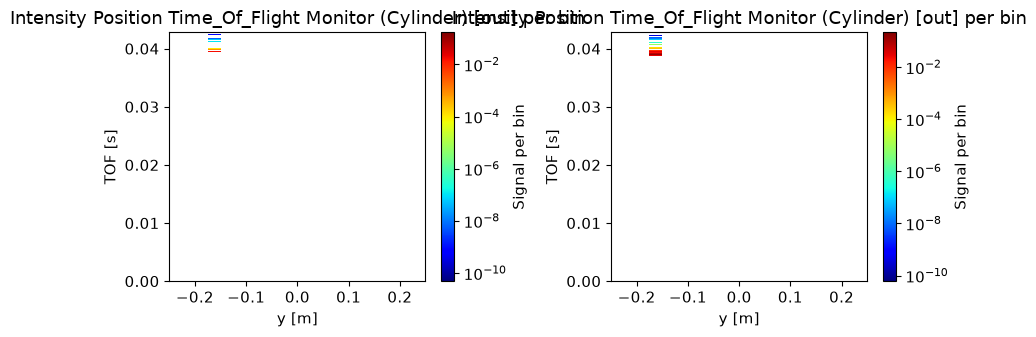

In [12]:
import os
import sys
from pathlib import Path

os.environ["MCSTAS_CC_OVERRIDE"] = "/usr/bin/gcc"
os.environ["MCSTAS_MPICC_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpicc")
os.environ["MCSTAS_MPIRUN_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpirun")
os.environ["OMPI_CC"] = "/usr/bin/gcc"
os.environ["MCSTAS_CFLAGS_OVERRIDE"] = "-O2 -march=x86-64 -mtune=generic -std=c99 -D_POSIX_SOURCE -lm"
os.environ["CFLAGS"] = ""
os.environ["LDFLAGS"] = ""

instr.settings(force_compile=True, ncount=1e8, mpi=12)
instr.write_full_instrument()
export_path = workspace / "one_channel_instrument.instr"
export_temp = export_path.with_suffix(".instr.tmp")
export_temp.write_bytes((Path(instr.input_path) / "one_channel_instrument.instr").read_bytes())
os.replace(export_temp, export_path)

print("Build directory:", instr.input_path)
print("ASCII output base:", instr.output_path)
data=instr.backengine()
ms.make_sub_plot(data,log=True)

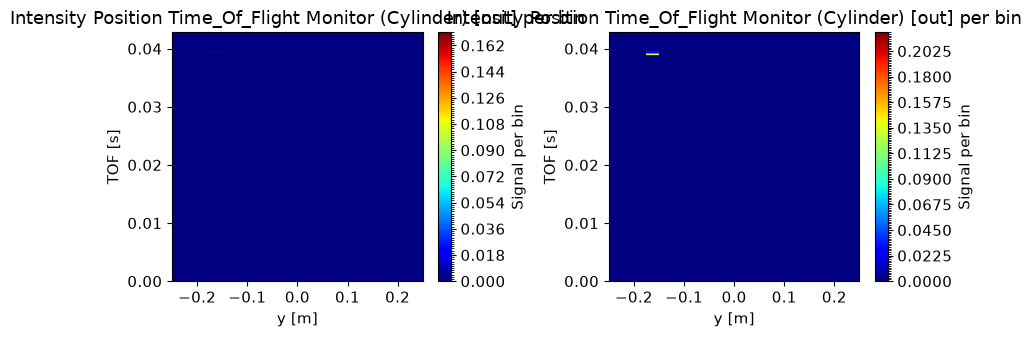

In [13]:
ms.make_sub_plot(data,log=False)